In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
DATASET_PATH = "att_faces"

print("Dataset path:", os.path.abspath(DATASET_PATH))
print("Dataset folder exists:", os.path.isdir(DATASET_PATH))

Dataset path: c:\Users\L\Downloads\202618029_DS605_Lab07\att_faces
Dataset folder exists: True


In [5]:
subject_folders = sorted(
    [
        folder
        for folder in os.listdir(DATASET_PATH)
        if folder.startswith("s")
        and folder[1:].isdigit()
        and os.path.isdir(os.path.join(DATASET_PATH, folder))
    ],
    key=lambda folder: int(folder[1:])
)

print("Number of subjects:", len(subject_folders))

for folder in subject_folders[:5]:
    folder_path = os.path.join(DATASET_PATH, folder)

    image_files = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(".pgm")
    ]

    print(folder, ":", len(image_files), "images")

Number of subjects: 40
s1 : 10 images
s2 : 10 images
s3 : 10 images
s4 : 10 images
s5 : 10 images


Image dimensions: (112, 92)
Data type: uint8
Minimum intensity: 11
Maximum intensity: 234
Number of pixels: 10304


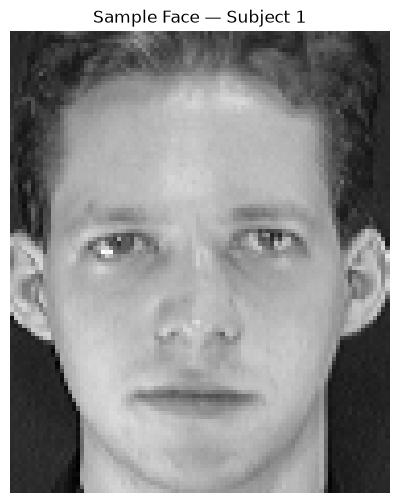

In [6]:
sample_path = os.path.join(DATASET_PATH, "s1", "1.pgm")

sample_image = Image.open(sample_path).convert("L")
sample_array = np.array(sample_image)

print("Image dimensions:", sample_array.shape)
print("Data type:", sample_array.dtype)
print("Minimum intensity:", sample_array.min())
print("Maximum intensity:", sample_array.max())
print("Number of pixels:", sample_array.size)

plt.figure(figsize=(5, 6))
plt.imshow(sample_array, cmap="gray")
plt.title("Sample Face — Subject 1")
plt.axis("off")
plt.show()

In [7]:
image_vector = sample_array.flatten()

print("Original image shape:", sample_array.shape)
print("Flattened vector shape:", image_vector.shape)

print("\nFirst 20 pixel values:")
print(image_vector[:20])

Original image shape: (112, 92)
Flattened vector shape: (10304,)

First 20 pixel values:
[48 49 45 47 49 57 39 42 53 49 53 60 76 91 99 95 80 75 66 54]


In [8]:
images = []
labels = []
image_paths = []

for subject_folder in subject_folders:

    subject_path = os.path.join(DATASET_PATH, subject_folder)
    subject_label = int(subject_folder[1:])

    image_files = sorted(
        [
            file for file in os.listdir(subject_path)
            if file.lower().endswith(".pgm")
        ],
        key=lambda file: int(os.path.splitext(file)[0])
    )

    for image_file in image_files:

        image_path = os.path.join(subject_path, image_file)

        image = Image.open(image_path).convert("L")
        image_array = np.array(image)

        images.append(image_array.flatten())
        labels.append(subject_label)
        image_paths.append(image_path)

X = np.array(images, dtype=np.float64)
y = np.array(labels)

print("Image matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of subjects:", len(np.unique(y)))
print("Total images:", len(X))

Image matrix shape: (400, 10304)
Labels shape: (400,)
Number of subjects: 40
Total images: 400


In [9]:
print("Unique subject labels:")
print(np.unique(y))

print("\nImages per subject:")
print(pd.Series(y).value_counts().sort_index())

Unique subject labels:
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]

Images per subject:
1     10
2     10
3     10
4     10
5     10
6     10
7     10
8     10
9     10
10    10
11    10
12    10
13    10
14    10
15    10
16    10
17    10
18    10
19    10
20    10
21    10
22    10
23    10
24    10
25    10
26    10
27    10
28    10
29    10
30    10
31    10
32    10
33    10
34    10
35    10
36    10
37    10
38    10
39    10
40    10
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

print("Training matrix:", X_train.shape)
print("Testing matrix:", X_test.shape)

print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))

Training images: 320
Testing images: 80
Training matrix: (320, 10304)
Testing matrix: (80, 10304)
Subjects in training: 40
Subjects in testing: 40


Part B — PCA, Eigenfaces, and Compression

Training matrix shape: (320, 10304)
Mean face vector shape: (10304,)


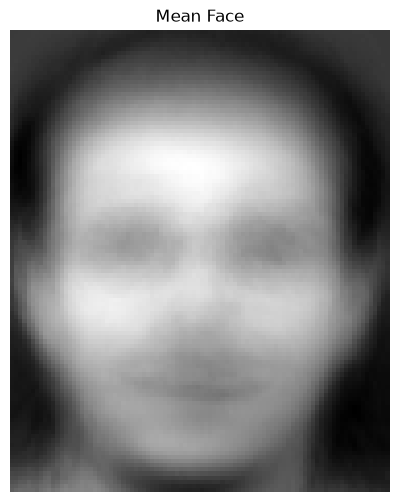

In [11]:
mean_face = np.mean(X_train, axis=0)

print("Training matrix shape:", X_train.shape)
print("Mean face vector shape:", mean_face.shape)

mean_face_image = mean_face.reshape(112, 92)

plt.figure(figsize=(5, 6))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [12]:

X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Centered training matrix:", X_train_centered.shape)
print("Centered testing matrix:", X_test_centered.shape)

print("Mean of centered training data:", np.mean(X_train_centered))

Centered training matrix: (320, 10304)
Centered testing matrix: (80, 10304)
Mean of centered training data: 0.0


In [13]:

N = X_train_centered.shape[0]

# Construct the dual covariance matrix
dual_covariance = (
    X_train_centered @ X_train_centered.T
) / (N - 1)

print("Dual covariance matrix shape:", dual_covariance.shape)

# Eigenvalue decomposition
eigenvalues_cov, eigenvectors_cov = np.linalg.eigh(
    dual_covariance
)

# Sort eigenvalues in descending order
sorted_indices = np.argsort(eigenvalues_cov)[::-1]

eigenvalues_cov = eigenvalues_cov[sorted_indices]
eigenvectors_cov = eigenvectors_cov[:, sorted_indices]

# Remove tiny numerical eigenvalues
tolerance = max(eigenvalues_cov[0], 1.0) * 1e-12
valid = eigenvalues_cov > tolerance

eigenvalues_cov = eigenvalues_cov[valid]
eigenvectors_cov = eigenvectors_cov[:, valid]

# Convert dual eigenvectors into pixel-space eigenvectors
eigenfaces_cov = (
    X_train_centered.T @ eigenvectors_cov
) / np.sqrt((N - 1) * eigenvalues_cov)

print("Number of nonzero principal directions:", len(eigenvalues_cov))
print("Eigenfaces matrix shape:", eigenfaces_cov.shape)

Dual covariance matrix shape: (320, 320)
Number of nonzero principal directions: 319
Eigenfaces matrix shape: (10304, 319)


In [14]:

U, singular_values, Vt = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Calculate the covariance eigenvalues
eigenvalues_svd = singular_values**2 / (N - 1)

# Principal directions in pixel space
eigenfaces_svd = Vt.T

print("U shape:", U.shape)
print("Singular values shape:", singular_values.shape)
print("V transpose shape:", Vt.shape)
print("Eigenfaces from SVD:", eigenfaces_svd.shape)

U shape: (320, 320)
Singular values shape: (320,)
V transpose shape: (320, 10304)
Eigenfaces from SVD: (10304, 320)


In [15]:

print("First 10 covariance eigenvalues:")
print(eigenvalues_cov[:10])

print("\nFirst 10 SVD covariance eigenvalues:")
print(eigenvalues_svd[:10])

count = min(
    len(eigenvalues_cov),
    len(eigenvalues_svd)
)

eigenvalue_difference = np.max(
    np.abs(
        eigenvalues_cov[:count]
        - eigenvalues_svd[:count]
    )
)

print("\nMaximum eigenvalue difference:", eigenvalue_difference)

# Compare the first 10 corresponding principal directions
num_compare = min(10, count)

direction_similarities = []

for i in range(num_compare):
    similarity = abs(
        np.dot(eigenfaces_cov[:, i], eigenfaces_svd[:, i])
    )
    direction_similarities.append(similarity)

print("\nAbsolute dot products for first 10 directions:")
print(np.round(direction_similarities, 6))

First 10 covariance eigenvalues:
[2881154.3084197  2069914.34945378 1093804.25057136  871380.92597549
  809594.92895779  545873.4796617   400892.48617877  378952.20963259
  312138.99678422  294529.97756797]

First 10 SVD covariance eigenvalues:
[2881154.30841969 2069914.34945378 1093804.25057136  871380.9259755
  809594.92895779  545873.4796617   400892.48617877  378952.20963259
  312138.99678422  294529.97756797]

Maximum eigenvalue difference: 7.450580596923828e-09

Absolute dot products for first 10 directions:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Components required for at least 90% variance: 98
Variance retained: 90.06 %


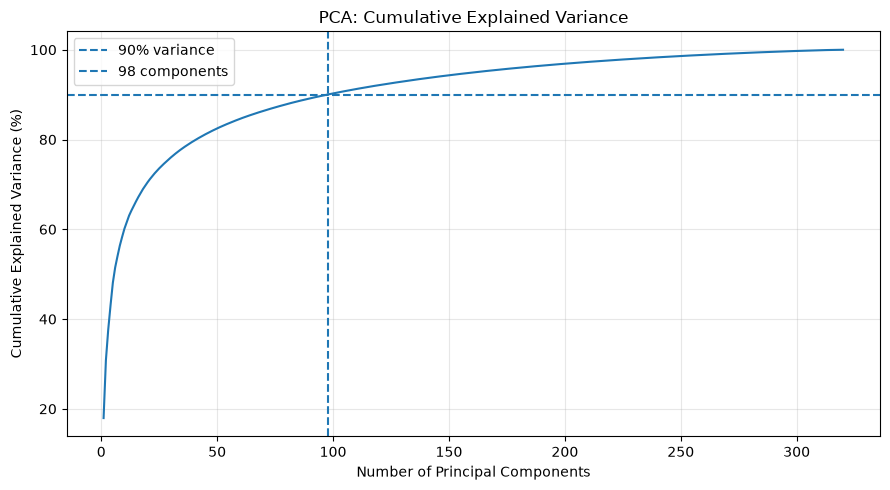

In [16]:

explained_variance_ratio = (
    eigenvalues_svd / np.sum(eigenvalues_svd)
)

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

# Find the minimum number of components needed for 90% variance
n_components_90 = np.searchsorted(
    cumulative_variance,
    0.90
) + 1

print(
    "Components required for at least 90% variance:",
    n_components_90
)

print(
    "Variance retained:",
    round(
        cumulative_variance[n_components_90 - 1] * 100,
        2
    ),
    "%"
)

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance"
)

plt.axvline(
    x=n_components_90,
    linestyle="--",
    label=f"{n_components_90} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Components required for at least 90% variance: 98
Variance retained: 90.06 %


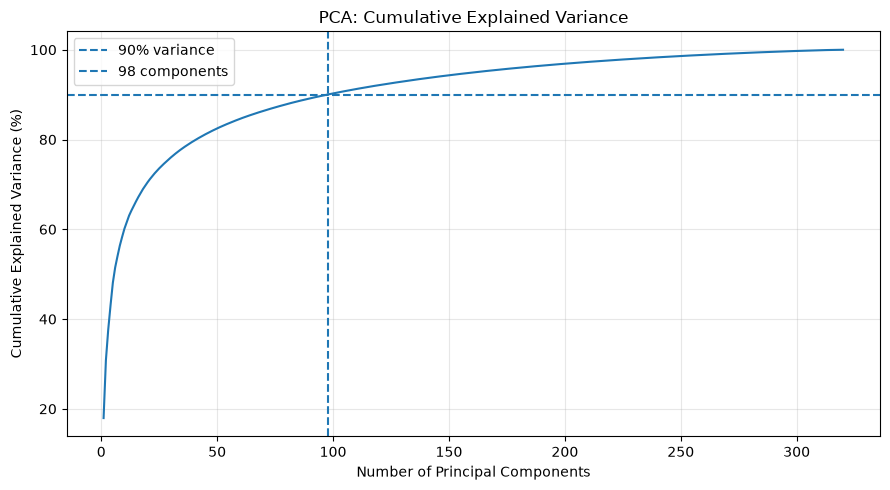

In [17]:

explained_variance_ratio = (
    eigenvalues_svd / np.sum(eigenvalues_svd)
)

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

# Find the minimum number of components needed for 90% variance
n_components_90 = np.searchsorted(
    cumulative_variance,
    0.90
) + 1

print(
    "Components required for at least 90% variance:",
    n_components_90
)

print(
    "Variance retained:",
    round(
        cumulative_variance[n_components_90 - 1] * 100,
        2
    ),
    "%"
)

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% variance"
)

plt.axvline(
    x=n_components_90,
    linestyle="--",
    label=f"{n_components_90} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:

W = eigenfaces_svd[:, :n_components_90]

Z_train = X_train_centered @ W
Z_test = X_test_centered @ W

print("Original training representation:", X_train.shape)
print("Reduced training representation:", Z_train.shape)

print("Original testing representation:", X_test.shape)
print("Reduced testing representation:", Z_test.shape)

print("Retained components:", n_components_90)

Original training representation: (320, 10304)
Reduced training representation: (320, 98)
Original testing representation: (80, 10304)
Reduced testing representation: (80, 98)
Retained components: 98


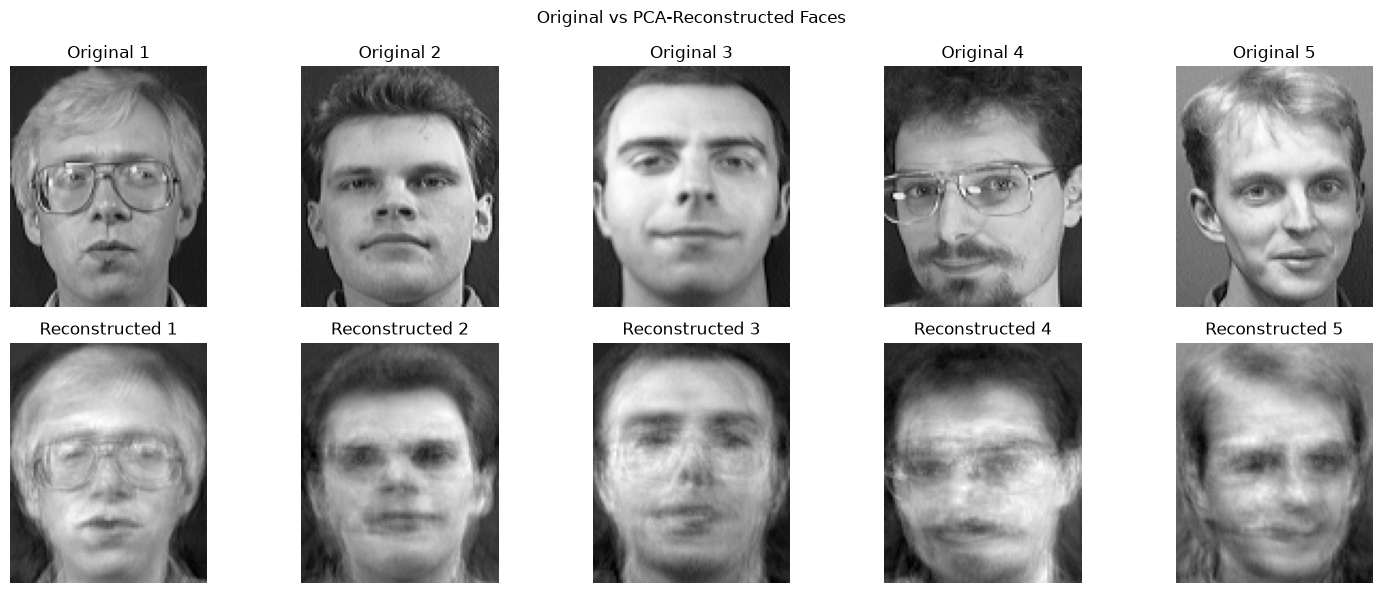

In [19]:

num_samples = 5

sample_original = X_test[:num_samples]

sample_reconstructed = (
    Z_test[:num_samples] @ W.T
) + mean_face

fig, axes = plt.subplots(
    2,
    num_samples,
    figsize=(15, 6)
)

for i in range(num_samples):

    axes[0, i].imshow(
        sample_original[i].reshape(112, 92),
        cmap="gray"
    )
    axes[0, i].set_title(f"Original {i + 1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        np.clip(
            sample_reconstructed[i].reshape(112, 92),
            0,
            255
        ),
        cmap="gray"
    )
    axes[1, i].set_title(f"Reconstructed {i + 1}")
    axes[1, i].axis("off")

plt.suptitle("Original vs PCA-Reconstructed Faces")
plt.tight_layout()
plt.show()

In [20]:

X_test_reconstructed = (
    Z_test @ W.T
) + mean_face

mse = np.mean(
    (X_test - X_test_reconstructed) ** 2
)

original_features = X_test.shape[1]
reduced_features = Z_test.shape[1]

# Per-image representation size, excluding the shared PCA model
compression_ratio = original_features / reduced_features

storage_reduction = (
    1 - reduced_features / original_features
) * 100

print("Original features per image:", original_features)
print("Reduced features per image:", reduced_features)

print("Reconstruction MSE:", round(mse, 4))
print("Feature compression ratio:", round(compression_ratio, 2), ":1")
print("Feature storage reduction:", round(storage_reduction, 2), "%")

Original features per image: 10304
Reduced features per image: 98
Reconstruction MSE: 329.983
Feature compression ratio: 105.14 :1
Feature storage reduction: 99.05 %


Part C

In [21]:
def pairwise_euclidean(A, B):
    A_sq = np.sum(A ** 2, axis=1, keepdims=True)
    B_sq = np.sum(B ** 2, axis=1, keepdims=True).T
    distances_squared = A_sq + B_sq - 2 * (A @ B.T)
    return np.sqrt(np.maximum(distances_squared, 0))


raw_distances = pairwise_euclidean(X_test, X_train)
raw_nearest_indices = np.argmin(raw_distances, axis=1)
raw_predictions = y_train[raw_nearest_indices]
raw_accuracy = np.mean(raw_predictions == y_test)

print("Raw Pixel Matching Accuracy:", round(raw_accuracy * 100, 2), "%")

Raw Pixel Matching Accuracy: 95.0 %


In [22]:
def pairwise_euclidean(A, B):
    A_sq = np.sum(A ** 2, axis=1, keepdims=True)
    B_sq = np.sum(B ** 2, axis=1, keepdims=True).T
    distances_squared = A_sq + B_sq - 2 * (A @ B.T)
    return np.sqrt(np.maximum(distances_squared, 0))


raw_distances = pairwise_euclidean(X_test, X_train)
raw_nearest_indices = np.argmin(raw_distances, axis=1)
raw_predictions = y_train[raw_nearest_indices]
raw_accuracy = np.mean(raw_predictions == y_test)

print("Raw Pixel Matching Accuracy:", round(raw_accuracy * 100, 2), "%")

Raw Pixel Matching Accuracy: 95.0 %


In [24]:
pca_distances = pairwise_euclidean(Z_test, Z_train)
pca_nearest_indices = np.argmin(pca_distances, axis=1)
pca_predictions = y_train[pca_nearest_indices]
pca_accuracy = np.mean(pca_predictions == y_test)

print("PCA Matching Accuracy:", round(pca_accuracy * 100, 2), "%")

PCA Matching Accuracy: 95.0 %


In [25]:
results_df = pd.DataFrame({
    "Actual_Subject": y_test,
    "Raw_Pixel_Prediction": raw_predictions,
    "Raw_Pixel_Correct": raw_predictions == y_test,
    "PCA_Prediction": pca_predictions,
    "PCA_Correct": pca_predictions == y_test,
    "Raw_Nearest_Train_Subject": y_train[raw_nearest_indices],
    "PCA_Nearest_Train_Subject": y_train[pca_nearest_indices]
})

results_df.index.name = "Test_Sample"
display(results_df)

,Actual_Subject,Raw_Pixel_Prediction,Raw_Pixel_Correct,PCA_Prediction,PCA_Correct,Raw_Nearest_Train_Subject,PCA_Nearest_Train_Subject
Test_Sample,,,,,,,
0,2,2,True,2,True,2,2
1,36,36,True,36,True,36,36
2,19,19,True,19,True,19,19
3,17,17,True,17,True,17,17
4,40,40,True,40,True,40,40
...,...,...,...,...,...,...,...
75,1,1,True,1,True,1,1
76,16,16,True,16,True,16,16
77,8,8,True,8,True,8,8


In [26]:
import os

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

results_df.to_csv("results/part_c_recognition_results.csv", index=True)

comparison_df = pd.DataFrame({
    "Method": ["Raw Pixel Matching", "PCA Matching"],
    "Accuracy": [raw_accuracy, pca_accuracy]
})

display(comparison_df)

,Method,Accuracy
0,Raw Pixel Matching,0.95
1,PCA Matching,0.95


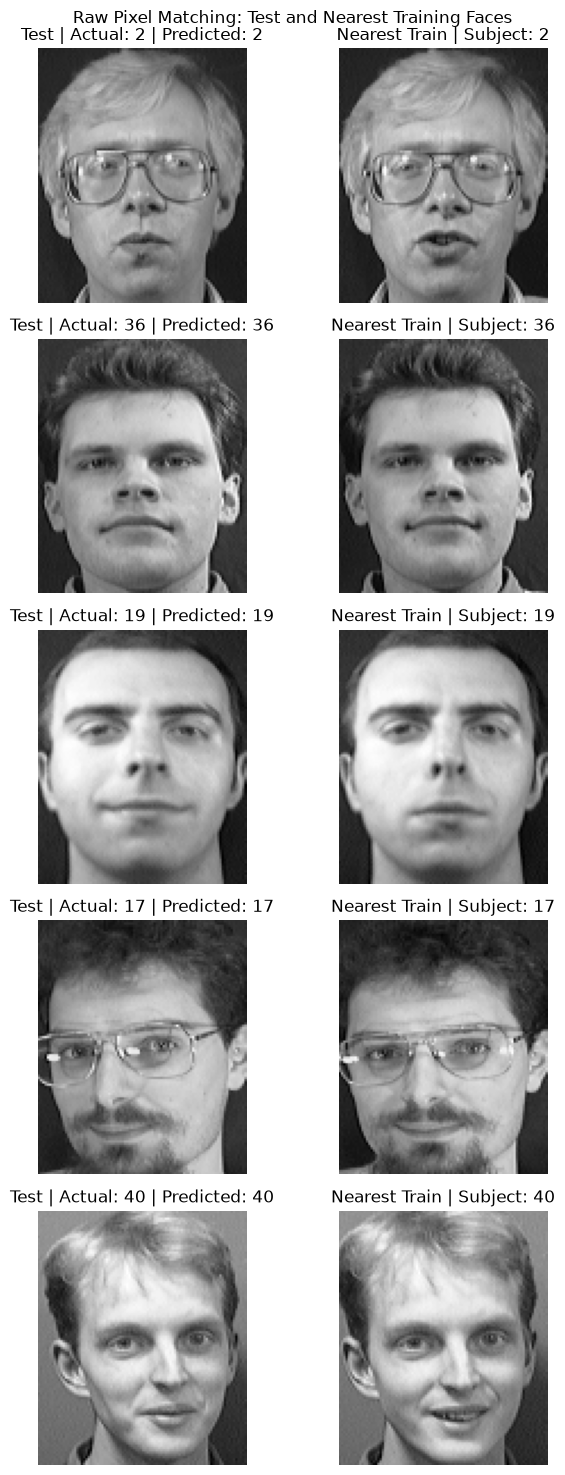

In [27]:
def show_matches(test_vectors, train_vectors, nearest_indices, actual_labels,
                 predicted_labels, title, number=5):
    correct_indices = np.where(actual_labels == predicted_labels)[0]
    incorrect_indices = np.where(actual_labels != predicted_labels)[0]

    selected_indices = list(correct_indices[:number])

    for idx in incorrect_indices:
        if len(selected_indices) >= number:
            break
        selected_indices.append(idx)

    if len(selected_indices) == 0:
        print("No samples available to display.")
        return

    fig, axes = plt.subplots(len(selected_indices), 2,
                             figsize=(7, 3 * len(selected_indices)))

    if len(selected_indices) == 1:
        axes = np.array([axes])

    for row, idx in enumerate(selected_indices):
        axes[row, 0].imshow(
            test_vectors[idx].reshape(112, 92), cmap="gray"
        )
        axes[row, 0].set_title(
            f"Test | Actual: {actual_labels[idx]} | Predicted: {predicted_labels[idx]}"
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(
            train_vectors[nearest_indices[idx]].reshape(112, 92),
            cmap="gray"
        )
        axes[row, 1].set_title(
            f"Nearest Train | Subject: {predicted_labels[idx]}"
        )
        axes[row, 1].axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_matches(
    X_test, X_train, raw_nearest_indices, y_test,
    raw_predictions, "Raw Pixel Matching: Test and Nearest Training Faces"
)

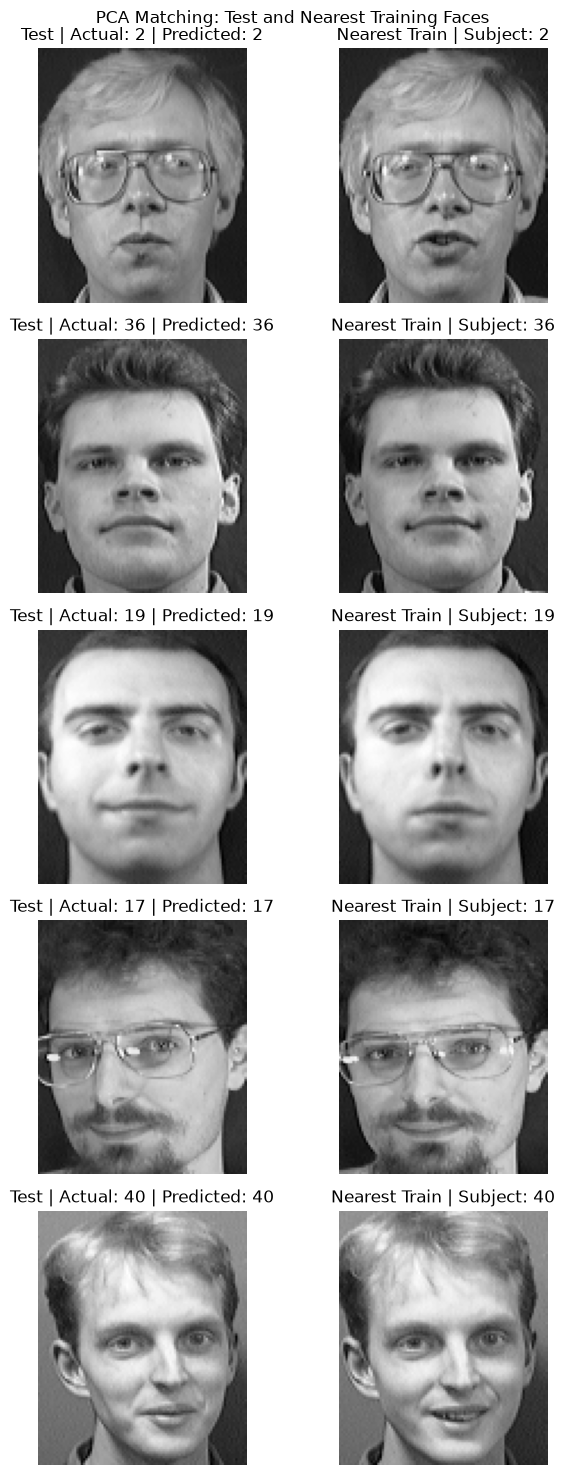

In [28]:
show_matches(
    X_test, X_train, pca_nearest_indices, y_test,
    pca_predictions, "PCA Matching: Test and Nearest Training Faces"
)

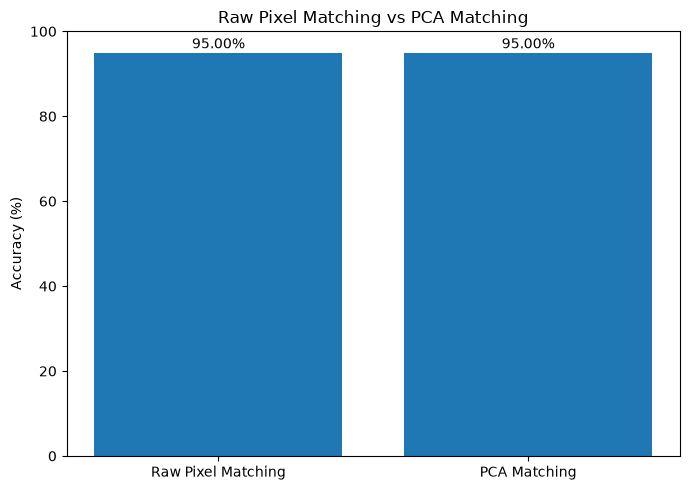

In [29]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    comparison_df["Method"],
    comparison_df["Accuracy"] * 100
)

ax.set_ylabel("Accuracy (%)")
ax.set_title("Raw Pixel Matching vs PCA Matching")
ax.set_ylim(0, 100)

for i, value in enumerate(comparison_df["Accuracy"] * 100):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.savefig("figures/part_c_matching_accuracy.png", dpi=300)
plt.show()

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(Z_train, y_train)
knn_predictions = knn_model.predict(Z_test)

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, gamma="scale")
)
svm_model.fit(Z_train, y_train)
svm_predictions = svm_model.predict(Z_test)

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, random_state=42)
)
lr_model.fit(Z_train, y_train)
lr_predictions = lr_model.predict(Z_test)

print("KNN Accuracy:", round(accuracy_score(y_test, knn_predictions) * 100, 2), "%")
print("SVM Accuracy:", round(accuracy_score(y_test, svm_predictions) * 100, 2), "%")
print("Logistic Regression Accuracy:", round(accuracy_score(y_test, lr_predictions) * 100, 2), "%")

KNN Accuracy: 91.25 %
SVM Accuracy: 95.0 %
Logistic Regression Accuracy: 95.0 %


In [31]:
models = {
    "PCA Nearest Face": pca_predictions,
    "KNN": knn_predictions,
    "SVM": svm_predictions,
    "Logistic Regression": lr_predictions
}

comparison_results = []

for model_name, predictions in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "F1_Score": f1_score(y_test, predictions, average="weighted", zero_division=0)
    })

ml_comparison_df = pd.DataFrame(comparison_results)
display(ml_comparison_df.round(4))

ml_comparison_df.to_csv("results/part_d_model_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1_Score
0,PCA Nearest Face,0.9500,0.9667,0.9500,0.9467
1,KNN,0.9125,0.9333,0.9125,0.9083
2,SVM,0.9500,0.9708,0.9500,0.9483
3,Logistic Regression,0.9500,0.9667,0.9500,0.9467


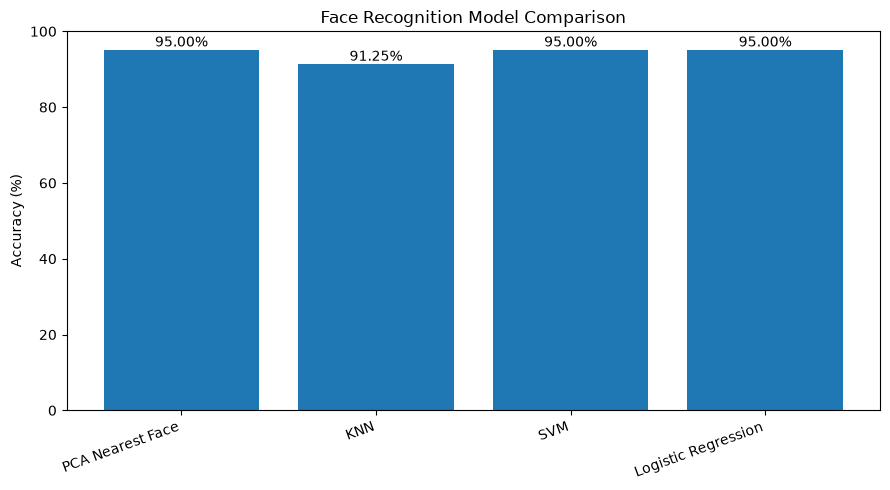

In [32]:
plt.figure(figsize=(9, 5))

plt.bar(
    ml_comparison_df["Model"],
    ml_comparison_df["Accuracy"] * 100
)

plt.ylabel("Accuracy (%)")
plt.title("Face Recognition Model Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")

for i, value in enumerate(ml_comparison_df["Accuracy"] * 100):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.savefig("figures/part_d_model_comparison.png", dpi=300)
plt.show()

In [33]:
component_counts = sorted(set([
    min(10, Z_train.shape[1]),
    min(20, Z_train.shape[1]),
    min(50, Z_train.shape[1]),
    min(100, Z_train.shape[1]),
    n_components_90
]))

component_results = []

for n_components in component_counts:
    W_current = eigenfaces_svd[:, :n_components]

    Z_train_current = X_train_centered @ W_current
    Z_test_current = X_test_centered @ W_current

    knn_current = KNeighborsClassifier(n_neighbors=3)
    knn_current.fit(Z_train_current, y_train)
    knn_current_predictions = knn_current.predict(Z_test_current)

    svm_current = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale")
    )
    svm_current.fit(Z_train_current, y_train)
    svm_current_predictions = svm_current.predict(Z_test_current)

    component_results.append({
        "Components": n_components,
        "Explained_Variance": cumulative_variance[n_components - 1],
        "KNN_Accuracy": accuracy_score(y_test, knn_current_predictions),
        "SVM_Accuracy": accuracy_score(y_test, svm_current_predictions)
    })

component_results_df = pd.DataFrame(component_results)
display(component_results_df.round(4))

component_results_df.to_csv("results/component_count_experiment.csv", index=False)

,Components,Explained_Variance,KNN_Accuracy,SVM_Accuracy
0,10,0.6014,0.8875,0.9500
1,20,0.7049,0.9250,0.9625
2,50,0.8248,0.9250,0.9750
3,98,0.9006,0.9125,0.9500


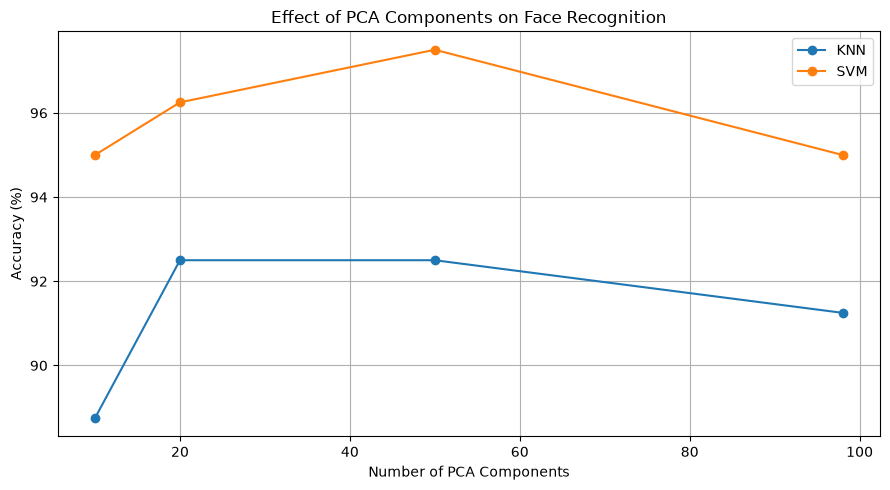

In [34]:
plt.figure(figsize=(9, 5))

plt.plot(
    component_results_df["Components"],
    component_results_df["KNN_Accuracy"] * 100,
    marker="o",
    label="KNN"
)

plt.plot(
    component_results_df["Components"],
    component_results_df["SVM_Accuracy"] * 100,
    marker="o",
    label="SVM"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Accuracy (%)")
plt.title("Effect of PCA Components on Face Recognition")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/component_count_experiment.png", dpi=300)
plt.show()

In [35]:
best_model_row = ml_comparison_df.loc[ml_comparison_df["Accuracy"].idxmax()]

print("Best Model:", best_model_row["Model"])
print("Accuracy:", round(best_model_row["Accuracy"] * 100, 2), "%")
print("Precision:", round(best_model_row["Precision"], 4))
print("Recall:", round(best_model_row["Recall"], 4))
print("F1 Score:", round(best_model_row["F1_Score"], 4))

print("\nClassification Report for Best Model:")

best_predictions = models[best_model_row["Model"]]

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Best Model: PCA Nearest Face
Accuracy: 95.0 %
Precision: 0.9667
Recall: 0.95
F1 Score: 0.9467

Classification Report for Best Model:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      0.50      0.67         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       1.00      0.50      0.67         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
  

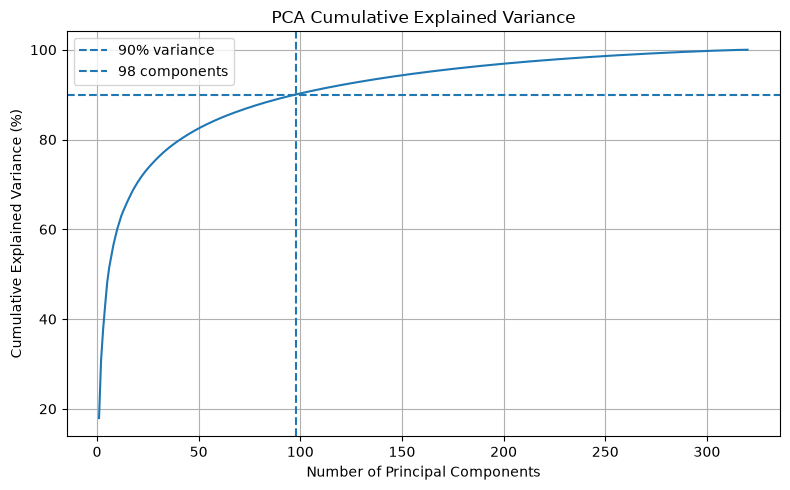

In [37]:
import os

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance * 100
)
plt.axhline(y=90, linestyle="--", label="90% variance")
plt.axvline(x=n_components_90, linestyle="--", label=f"{n_components_90} components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/explained_variance.png", dpi=300)
plt.show()

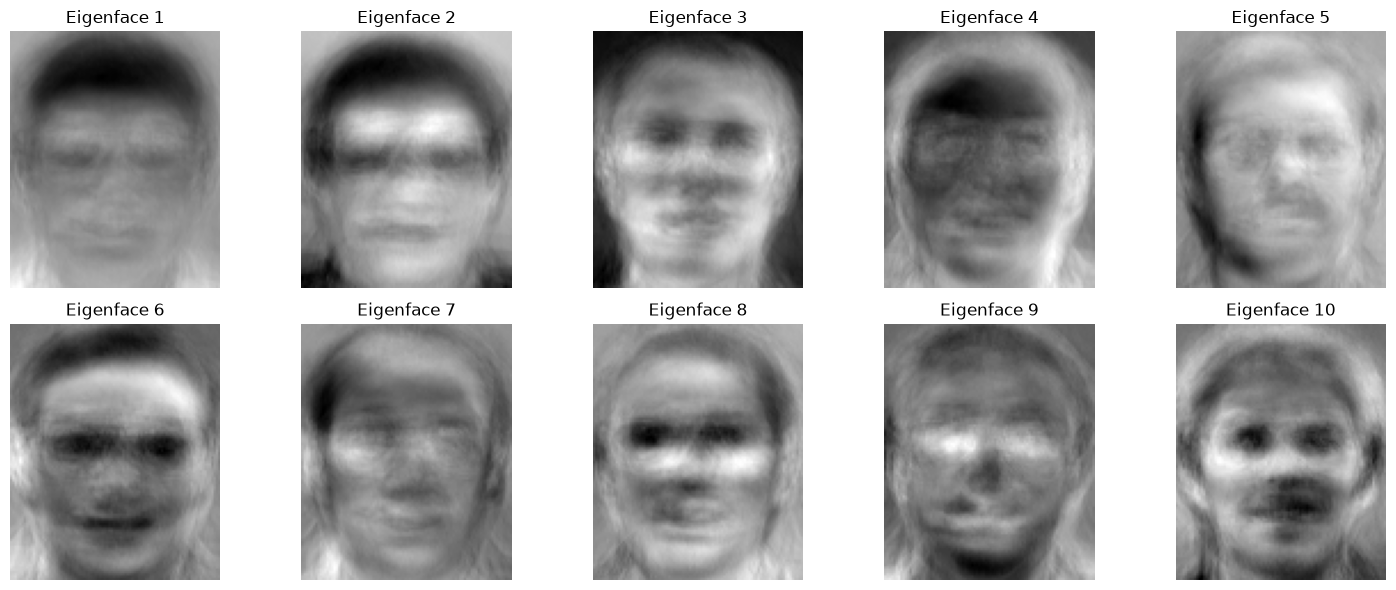

In [38]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(eigenfaces_svd[:, i].reshape(112, 92), cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/eigenfaces.png", dpi=300)
plt.show()

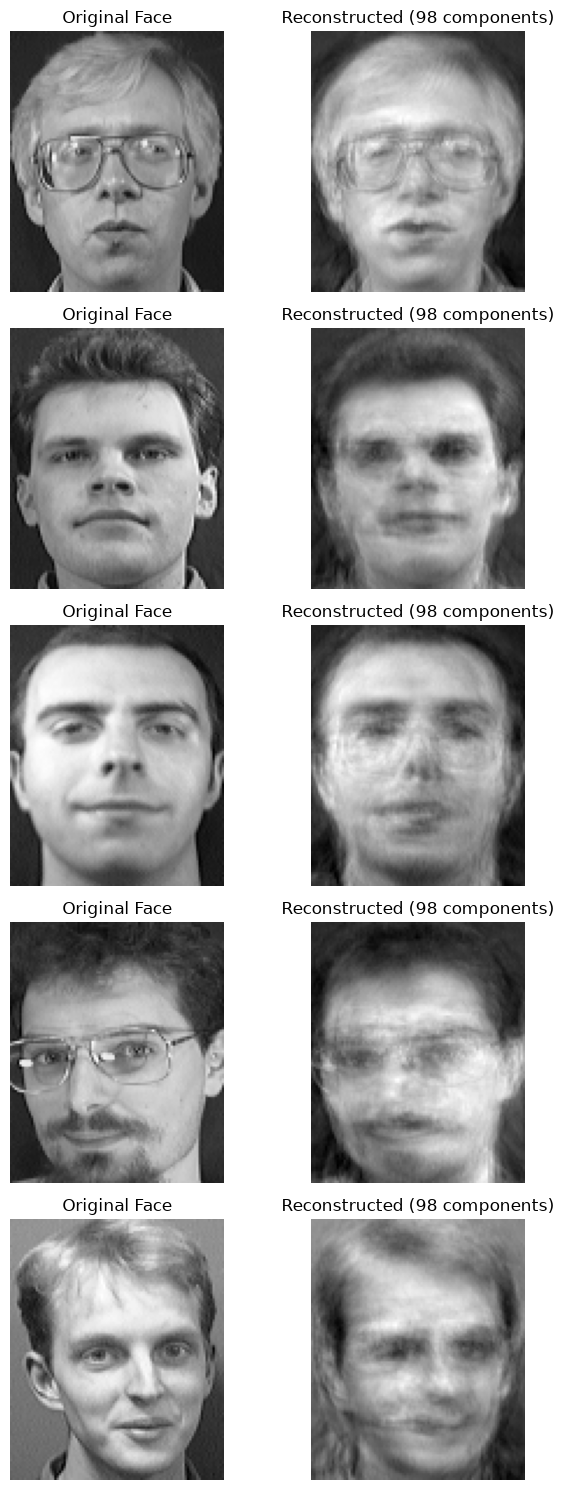

In [39]:
num_samples = min(5, len(X_test))

reconstructed_faces = (
    Z_test[:num_samples] @ W.T
) + mean_face

fig, axes = plt.subplots(num_samples, 2, figsize=(7, 3 * num_samples))

if num_samples == 1:
    axes = np.array([axes])

for i in range(num_samples):
    axes[i, 0].imshow(X_test[i].reshape(112, 92), cmap="gray")
    axes[i, 0].set_title("Original Face")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        np.clip(reconstructed_faces[i].reshape(112, 92), 0, 255),
        cmap="gray"
    )
    axes[i, 1].set_title(f"Reconstructed ({n_components_90} components)")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig("figures/reconstruction_examples.png", dpi=300)
plt.show()

In [40]:
summary_df = pd.DataFrame({
    "Metric": [
        "Total Images",
        "Number of Subjects",
        "Image Height",
        "Image Width",
        "Original Features per Image",
        "Training Images",
        "Testing Images",
        "PCA Components for 90% Variance",
        "Explained Variance Retained (%)",
        "Raw Pixel Matching Accuracy (%)",
        "PCA Matching Accuracy (%)",
        "Best ML Model",
        "Best ML Accuracy (%)"
    ],
    "Value": [
        len(X),
        len(np.unique(y)),
        112,
        92,
        X.shape[1],
        len(X_train),
        len(X_test),
        n_components_90,
        round(cumulative_variance[n_components_90 - 1] * 100, 2),
        round(raw_accuracy * 100, 2),
        round(pca_accuracy * 100, 2),
        best_model_row["Model"],
        round(best_model_row["Accuracy"] * 100, 2)
    ]
})

display(summary_df)
summary_df.to_csv("results/project_summary.csv", index=False)

,Metric,Value
0,Total Images,400
1,Number of Subjects,40
2,Image Height,112
3,Image Width,92
4,Original Features per Image,10304
5,Training Images,320
6,Testing Images,80
7,PCA Components for 90% Variance,98
8,Explained Variance Retained (%),90.06
9,Raw Pixel Matching Accuracy (%),95.0


In [41]:
for folder in ["figures", "results"]:
    print(f"\n{folder.upper()}")

    for filename in sorted(os.listdir(folder)):
        print(filename)


FIGURES
component_count_experiment.png
eigenfaces.png
explained_variance.png
part_c_matching_accuracy.png
part_d_model_comparison.png
reconstruction_examples.png

RESULTS
component_count_experiment.csv
part_c_recognition_results.csv
part_d_model_comparison.csv
project_summary.csv


In [42]:
import os
import shutil

os.makedirs("DS605_Lab07_Submission/figures", exist_ok=True)
os.makedirs("DS605_Lab07_Submission/results", exist_ok=True)

for filename in [
    "explained_variance.png",
    "eigenfaces.png",
    "reconstruction_examples.png",
    "part_c_matching_accuracy.png",
    "part_d_model_comparison.png",
    "component_count_experiment.png"
]:
    source = os.path.join("figures", filename)
    if os.path.exists(source):
        shutil.copy2(
            source,
            os.path.join("DS605_Lab07_Submission/figures", filename)
        )

for filename in [
    "part_c_recognition_results.csv",
    "part_d_model_comparison.csv",
    "component_count_experiment.csv",
    "project_summary.csv"
]:
    source = os.path.join("results", filename)
    if os.path.exists(source):
        shutil.copy2(
            source,
            os.path.join("DS605_Lab07_Submission/results", filename)
        )

print("Submission folders prepared.")

Submission folders prepared.


In [43]:
import os

for root, dirs, files in os.walk("DS605_Lab07_Submission"):
    print(root)
    for filename in sorted(files):
        print("   ", filename)

DS605_Lab07_Submission
DS605_Lab07_Submission\figures
    component_count_experiment.png
    eigenfaces.png
    explained_variance.png
    part_c_matching_accuracy.png
    part_d_model_comparison.png
    reconstruction_examples.png
DS605_Lab07_Submission\results
    component_count_experiment.csv
    part_c_recognition_results.csv
    part_d_model_comparison.csv
    project_summary.csv


In [44]:
import json

submission_info = {
    "project": "Image Representation, PCA, Eigenfaces and Face Recognition",
    "course": "DS605",
    "dataset": "AT&T Database of Faces (ORL)",
    "total_images": int(len(X)),
    "total_subjects": int(len(np.unique(y))),
    "image_dimensions": [112, 92],
    "original_features_per_image": int(X.shape[1]),
    "training_images": int(len(X_train)),
    "testing_images": int(len(X_test)),
    "pca_components_for_90_percent_variance": int(n_components_90),
    "explained_variance_percent": round(
        float(cumulative_variance[n_components_90 - 1] * 100), 2
    ),
    "raw_pixel_matching_accuracy_percent": round(float(raw_accuracy * 100), 2),
    "pca_matching_accuracy_percent": round(float(pca_accuracy * 100), 2),
    "best_ml_model": str(best_model_row["Model"]),
    "best_ml_accuracy_percent": round(float(best_model_row["Accuracy"] * 100), 2)
}

with open("DS605_Lab07_Submission/results/project_summary.json", "w") as f:
    json.dump(submission_info, f, indent=4)

print("Project summary saved.")

Project summary saved.
